In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from scipy.optimize import minimize

# Question 1

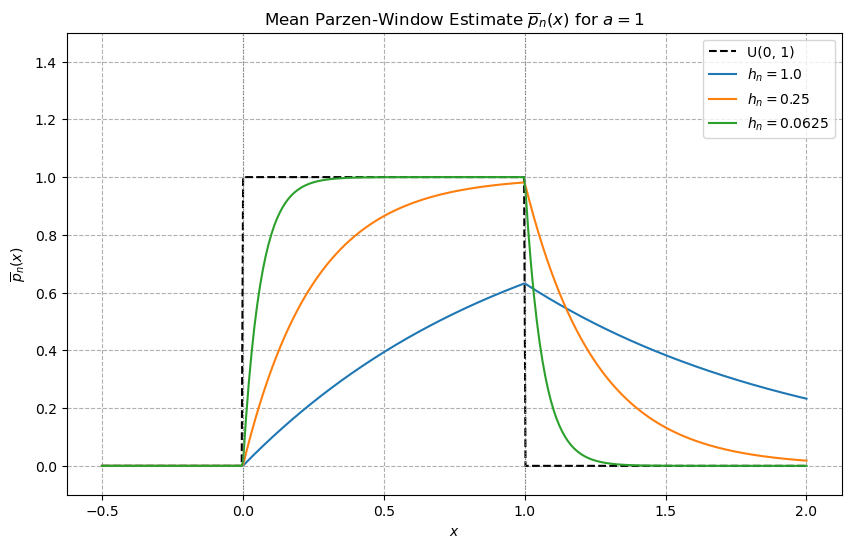

In [2]:
a = 1.0
h_values = [1.0, 0.25, 0.0625]

def mean_parzen_estimate(x, a, h_n):
    if x < 0:
        return 0.0
    elif 0 <= x <= a:
        return (1.0 / a) * (1.0 - np.exp(-x / h_n))
    else:
        return (1.0 / a) * (np.exp(a / h_n) - 1.0) * np.exp(-x / h_n)

x_range = np.linspace(-0.5, 2.0, 500)
true_p_x = np.where((x_range >= 0) & (x_range <= a), 1.0/a, 0.0)

plt.figure(figsize=(10, 6))
plt.plot(x_range, true_p_x, 'k--', label=r'U(0, 1)')

for h_n in h_values:
    y_values = np.array([mean_parzen_estimate(x, a, h_n) for x in x_range])
    plt.plot(x_range, y_values, label=r'$h_n = ' + str(h_n) + '$')

plt.title(r'Mean Parzen-Window Estimate $\overline{p}_n(x)$ for $a=1$')
plt.xlabel(r'$x$')
plt.ylabel(r'$\overline{p}_n(x)$')
plt.grid(True, linestyle='--')
plt.legend()
plt.ylim(-0.1, 1.5)
plt.axvline(x=0, color='gray', linestyle=':', linewidth=0.8)
plt.axvline(x=a, color='gray', linestyle=':', linewidth=0.8)
plt.show()

Required h_n for a < 1% bias over 99% of range [0, 1]: h_n = 0.00217


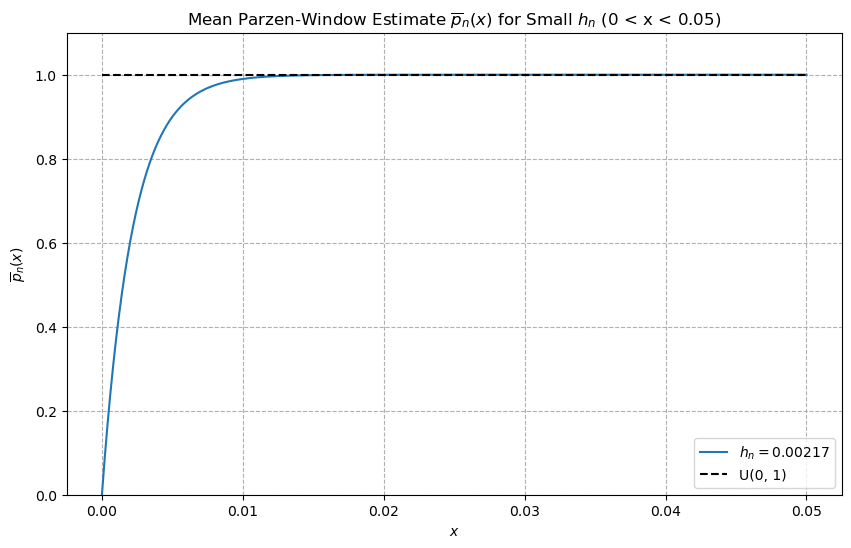

In [3]:
h_4 = 0.01 / (-np.log(0.01))
print(f"Required h_n for a < 1% bias over 99% of range [0, 1]: h_n = {h_4:.5f}")

x_range_4 = np.linspace(0.0, 0.05, 500)
y_values_4 = np.array([mean_parzen_estimate(x, a, h_4) for x in x_range_4])

plt.figure(figsize=(10, 6))
plt.plot(x_range_4, y_values_4, label=r'$h_n = 0.00217$')

true_p_x_4 = np.where((x_range_4 >= 0) & (x_range_4 <= a), 1.0/a, 0.0)
plt.plot(x_range_4, true_p_x_4, 'k--', label=r'U(0, 1)')

plt.title(r'Mean Parzen-Window Estimate $\overline{p}_n(x)$ for Small $h_n$ (0 < x < 0.05)')
plt.xlabel(r'$x$')
plt.ylabel(r'$\overline{p}_n(x)$')
plt.grid(True, linestyle='--')
plt.legend()
plt.ylim(0, 1.1)
plt.show()

# Question 10

In [4]:
w1 = np.array([
    [0.28, 1.31, -6.2], [0.07, 0.58, -0.78], [1.54, 2.01, -1.63],
    [-0.44, 1.18, -4.32], [-0.81, 0.21, 5.73], [1.52, 3.16, 2.77],
    [2.20, 2.42, -0.19], [0.91, 1.94, 6.21], [0.65, 1.93, 4.38],
    [-0.26, 0.82, -0.96]
])
w2 = np.array([
    [0.011, 1.03, -0.21], [1.27, 1.28, 0.08], [0.13, 3.12, 0.16],
    [-0.21, 1.23, -0.11], [-2.18, 1.39, -0.19], [0.34, 1.96, -0.16],
    [-1.38, 0.94, 0.45], [-0.12, 0.82, 0.17], [-1.44, 2.31, 0.14],
    [0.26, 1.94, 0.08]
])
w3 = np.array([
    [1.36, 2.17, 0.14], [1.41, 1.45, -0.38], [1.22, 0.99, 0.69],
    [2.46, 2.19, 1.31], [0.68, 0.79, 0.87], [2.51, 3.22, 1.35],
    [2.60, 2.44, 0.92], [0.64, 0.13, 0.97], [0.85, 0.58, 0.99],
    [0.66, 0.51, 0.88]
])

test_points = np.array([
    [0.50, 1.0, 0.0],
    [0.31, 1.51, -0.50],
    [-0.3, 0.44, -0.1]
])

def parzen_classify(h):
    results = []
    for x in test_points:
        #p(x|w_i) ~ sum(exp(-||x-xi||^2 / 2h^2))
        score1 = np.sum(np.exp(-np.sum((w1 - x)**2, axis=1) / (2 * h**2)))
        score2 = np.sum(np.exp(-np.sum((w2 - x)**2, axis=1) / (2 * h**2)))
        score3 = np.sum(np.exp(-np.sum((w3 - x)**2, axis=1) / (2 * h**2)))
        
        scores = [score1, score2, score3]
        winner = np.argmax(scores) + 1
        results.append((scores, winner))
    return results

q10_res_h1 = parzen_classify(1.0)
q10_res_h01 = parzen_classify(0.1)
print(f"{q10_res_h1=}")
print(f"{q10_res_h01=}")

q10_res_h1=[([1.2591897997233061, 4.710784993854763, 3.7746557035068116], 2), ([1.5343855472566377, 4.827963275034261, 2.050403178919641], 2), ([1.3990811894977488, 3.782543279501114, 1.7706635724728121], 2)]
q10_res_h01=[([8.77469530673296e-22, 6.769019526350557e-07, 8.000188850603628e-19], 2), ([2.8711163529583766e-22, 1.200183821939926e-07, 2.1593289688030122e-27], 2), ([3.63712276104245e-14, 3.7830940387857954e-06, 1.0640260760706517e-41], 2)]


# Question 11

In [5]:
data = np.fromfile('normal.data.txt', sep=' ')
n_samples = len(data)

mu_mle = np.mean(data)
sigma2_mle = np.var(data)
sigma_mle = np.sqrt(sigma2_mle)

def neg_log_likelihood(params):
    mu, s2 = params
    if s2 <= 0: return np.inf
    #NLL = (N/2)ln(2pi) + (N/2)ln(s2) + (1/2s2)sum(xi-mu)^2
    return 0.5 * n_samples * np.log(2 * np.pi * s2) + np.sum((data - mu)**2) / (2 * s2)

res_opt = minimize(neg_log_likelihood, x0=[100, 100], method='Nelder-Mead')
mu_num, sigma2_num = res_opt.x

fisher_info_inv = np.array([
    [sigma2_mle / n_samples, 0],
    [0, 2 * (sigma2_mle**2) / n_samples]
])

se_sigma2 = np.sqrt(fisher_info_inv[1, 1])
ci_sigma2 = [sigma2_mle - 1.96 * se_sigma2, sigma2_mle + 1.96 * se_sigma2]

mu_0 = 103

z_stat = (mu_mle - mu_0) / (np.sqrt(sigma2_mle) / np.sqrt(n_samples))
p_z = 2 * (1 - stats.norm.cdf(abs(z_stat)))

sigma2_0_mle = np.mean((data - mu_0)**2)
ll_1 = -neg_log_likelihood([mu_mle, sigma2_mle])
ll_0 = -neg_log_likelihood([mu_0, sigma2_0_mle])
lrt_stat = -2 * (ll_0 - ll_1)
p_lrt = 1 - stats.chi2.cdf(lrt_stat, df=1)

wald_stat = (mu_mle - mu_0)**2 / (sigma2_mle / n_samples)
p_wald = 1 - stats.chi2.cdf(wald_stat, df=1)

cv_est = sigma_mle / mu_mle

grad_g = np.array([-sigma_mle / (mu_mle**2), 1 / (2 * mu_mle * sigma_mle)])
var_cv = grad_g.T @ fisher_info_inv @ grad_g
se_cv = np.sqrt(var_cv)
ci_cv = [cv_est - 1.96 * se_cv, cv_est + 1.96 * se_cv]

print(f"{mu_mle=}")
print(f"{mu_num=}")
print(f"{sigma2_mle=}")
print(f"{sigma2_num=}")
print(f"{ci_sigma2=}")
print(f"{z_stat=}, {p_z=}")
print(f"{lrt_stat=}, {p_lrt=}")
print(f"{wald_stat=}, {p_wald=}")
print(f"{cv_est=}, {ci_cv=}")

mu_mle=100.48049999999999
mu_num=100.48049890228016
sigma2_mle=216.31846975
sigma2_num=216.31850481762973
ci_sigma2=[173.920049679, 258.716889821]
z_stat=-2.4226047226272107, p_z=0.0154096835916544
lrt_stat=5.784548778596445, p_lrt=0.016167647516078798
wald_stat=5.869013642095663, p_wald=0.015409683591654288
cv_est=0.14637436146263474, ci_cv=[0.1317255563598098, 0.1610231665654597]


# Question 12

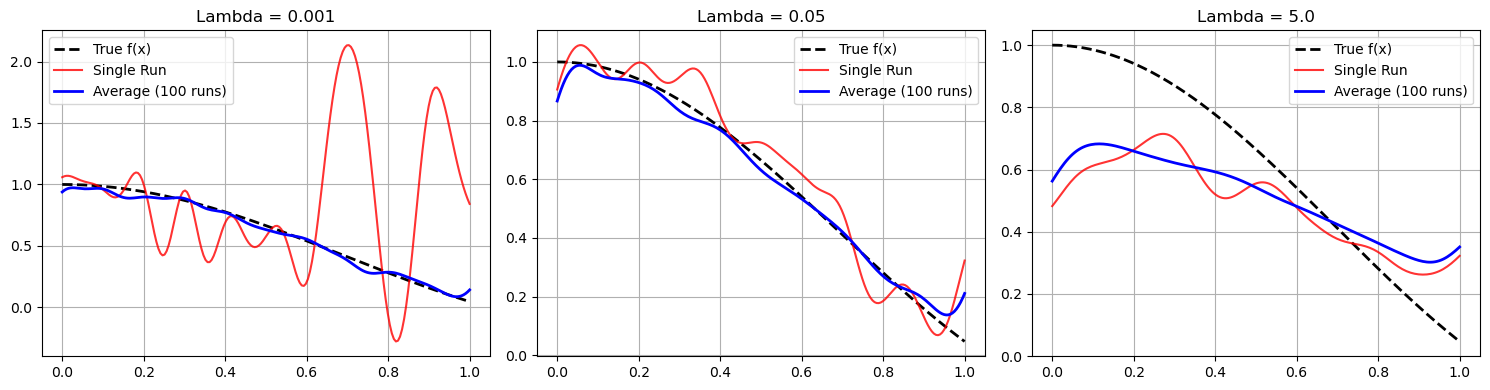

In [6]:
np.random.seed(2)

def true_f(x):
    x = np.atleast_1d(x) 
    res = np.ones_like(x)
    mask = x != 0
    res[mask] = np.sin(3 * x[mask]) / (3 * x[mask]) #using a mask to avoid division by zero warning
    return res

means = np.linspace(0, 1, 21)
sigma_basis = 0.04

def get_design_matrix(x_vec):
    n = len(x_vec)
    H = np.ones((n, 22)) 
    for j in range(21):
        #gaussian basis formula: exp(-(x-mu)^2 / 2*sigma^2)
        H[:, j+1] = np.exp(-((x_vec - means[j])**2) / (2 * sigma_basis**2))
    return H

n_samples = 25
noise_var = 0.01
lambdas = [0.001, 0.05, 5.0]
n_repeats = 100

x_test = np.linspace(0, 1, 200)
y_true_test = true_f(x_test)
H_test = get_design_matrix(x_test)

plt.figure(figsize=(15, 4))

for idx, lam in enumerate(lambdas):
    all_preds = []
    
    for i in range(n_repeats):
        x_train = np.random.uniform(0, 1, n_samples)
        y_train = true_f(x_train) + np.random.normal(0, np.sqrt(noise_var), n_samples)
        
        H_train = get_design_matrix(x_train)
        
        #ridge: beta = (H'H + lam*I)^-1 H'y
        I = np.eye(22)
        beta = np.linalg.inv(H_train.T @ H_train + lam * I) @ H_train.T @ y_train
        
        y_pred = H_test @ beta
        all_preds.append(y_pred)
        
        if i == 0:
            single_run = y_pred

    avg_pred = np.mean(all_preds, axis=0)

    plt.subplot(1, 3, idx + 1)
    plt.plot(x_test, y_true_test, 'k--', label='True f(x)', linewidth=2)
    plt.plot(x_test, single_run, 'r-', label='Single Run', alpha=0.8)
    plt.plot(x_test, avg_pred, 'b-', label='Average (100 runs)', linewidth=2)
    plt.title(f'Lambda = {lam}')
    plt.legend()
    
    plt.grid(True)
plt.tight_layout()
plt.show()


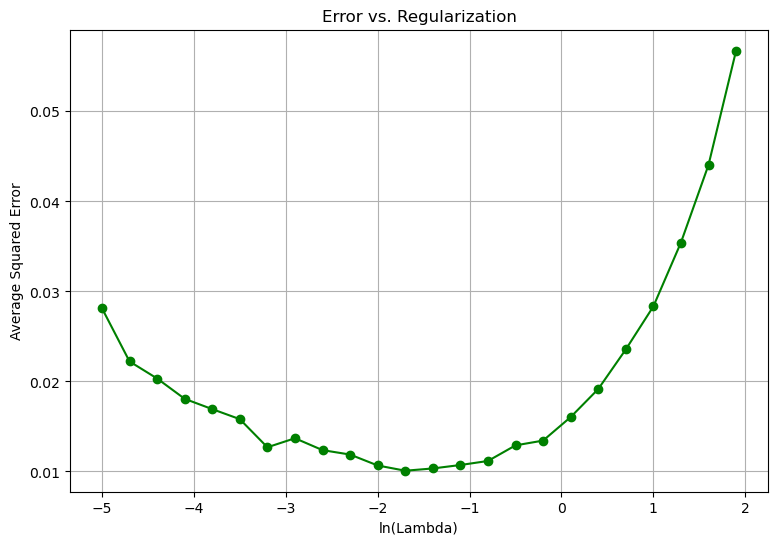

In [7]:
np.random.seed(2)
lambda_range = np.exp(np.arange(-5, 2.0001, 0.3))
avg_errors = []

for lam in lambda_range:
    mse_list = []
    for _ in range(100):
        x_train = np.random.uniform(0, 1, n_samples)
        y_train = true_f(x_train) + np.random.normal(0, np.sqrt(noise_var), n_samples)
        
        H_train = get_design_matrix(x_train)
        beta = np.linalg.inv(H_train.T @ H_train + lam * np.eye(22)) @ H_train.T @ y_train
        
        mse = np.mean((y_true_test - H_test @ beta)**2)
        mse_list.append(mse)
    avg_errors.append(np.mean(mse_list))

plt.figure(figsize=(9,6))
plt.plot(np.log(lambda_range), avg_errors, 'g-o')
plt.xlabel('ln(Lambda)')
plt.ylabel('Average Squared Error')
plt.title('Error vs. Regularization')
plt.grid(True)
plt.show()